In [21]:

import os

ROOT = '/kaggle/input/datasets/sakethbirru/medical-dataset'

print("Files and folders:")
for item in os.listdir(ROOT):
    print(item)


Files and folders:
medical_dataset (1).csv


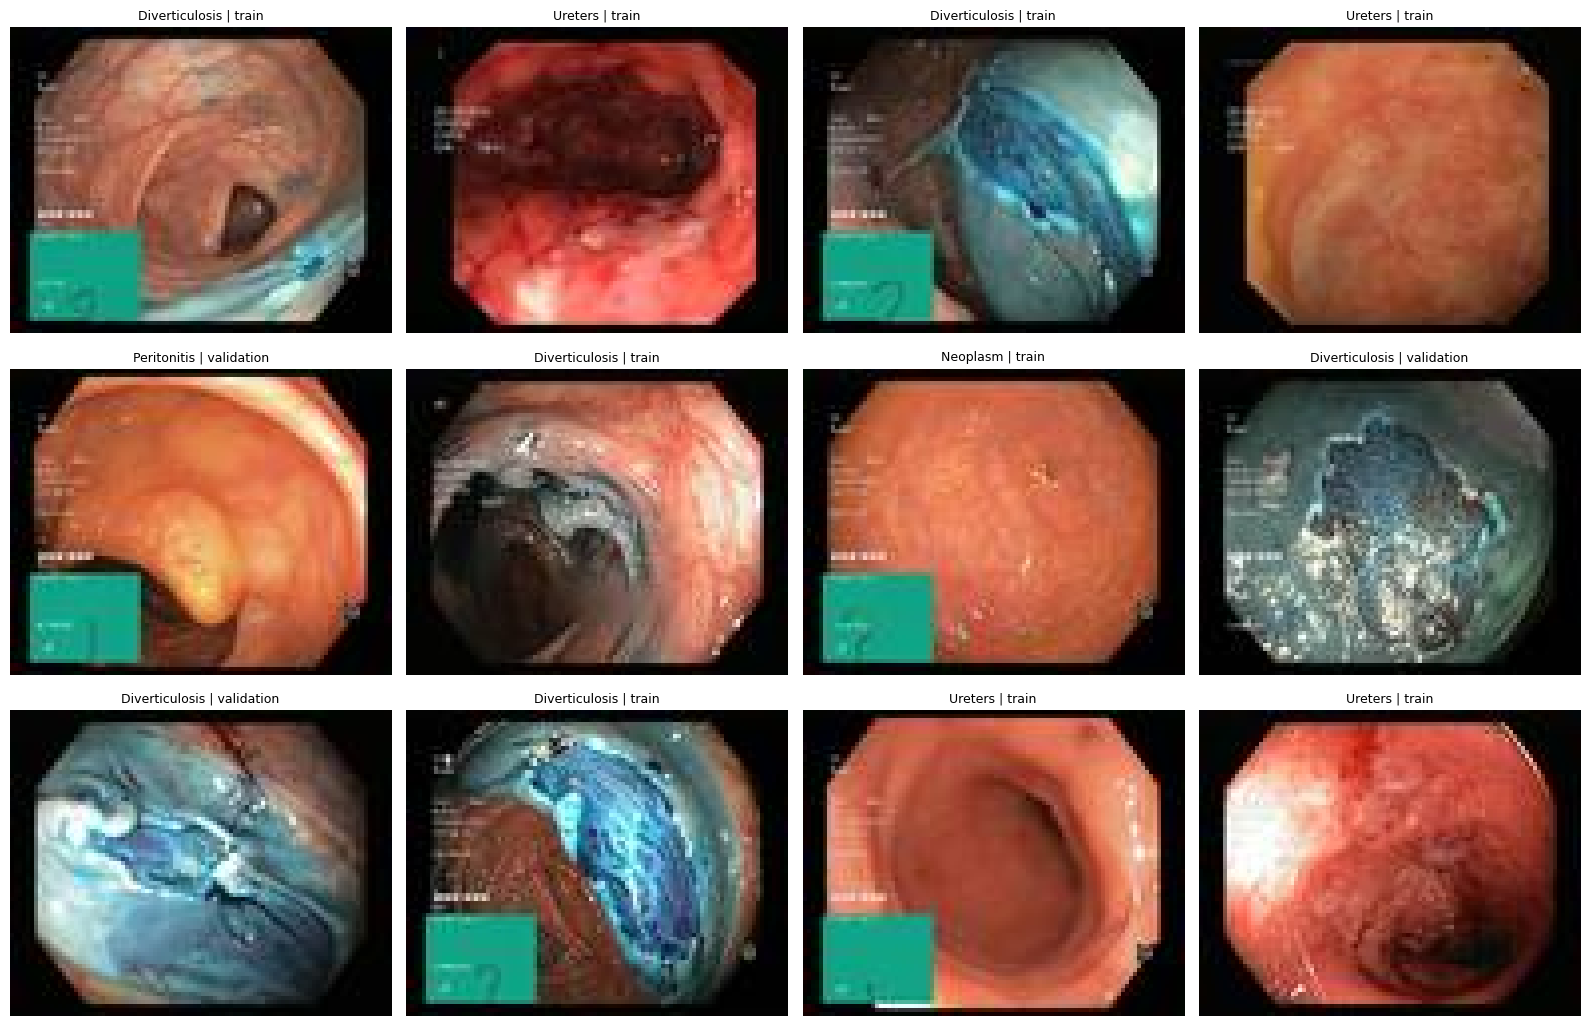

In [22]:

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
import base64
import math

def show_images(data, n=12, cols=4, seed=42):
    sample = data.sample(min(n, len(data)), random_state=seed)
    rows = math.ceil(len(sample) / cols)

    fig, axes = plt.subplots(
        rows, cols, figsize=(4 * cols, 3.5 * rows), squeeze=False
    )

    for ax in axes.flat:
        ax.axis('off')

    for ax, (_, r) in zip(axes.flat, sample.iterrows()):
        try:
            encoded = r['thumbnail'].split(',', 1)[1]
            img_bytes = base64.b64decode(encoded)
            img = Image.open(BytesIO(img_bytes))
            ax.imshow(img)
            ax.set_title(f"{r['label']} | {r['split']}", fontsize=9)
        except Exception as e:
            ax.set_title(f"Could not load: {e}", fontsize=8)

    plt.tight_layout()
    plt.show()

show_images(df, n=12)


Class: Diverticulosis


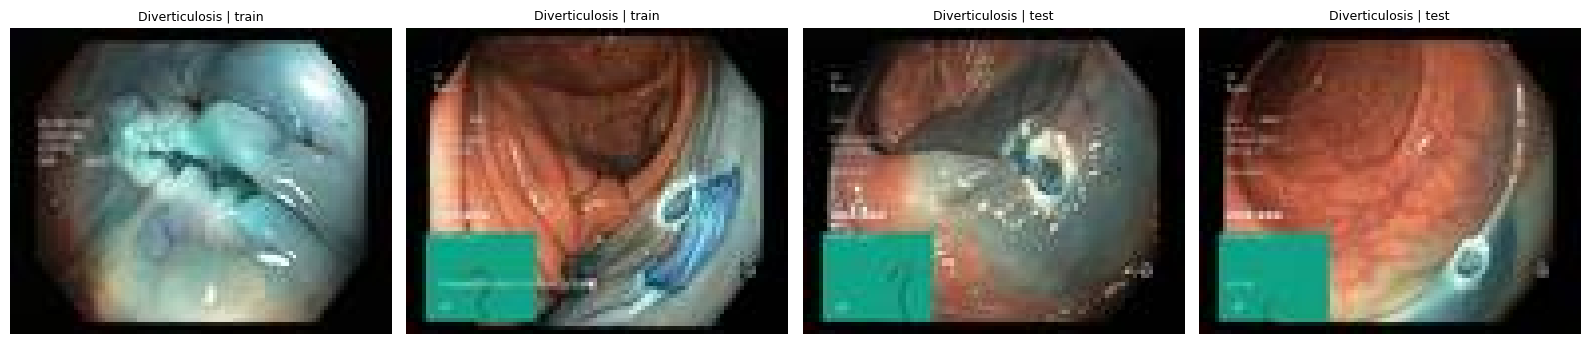

Class: Neoplasm


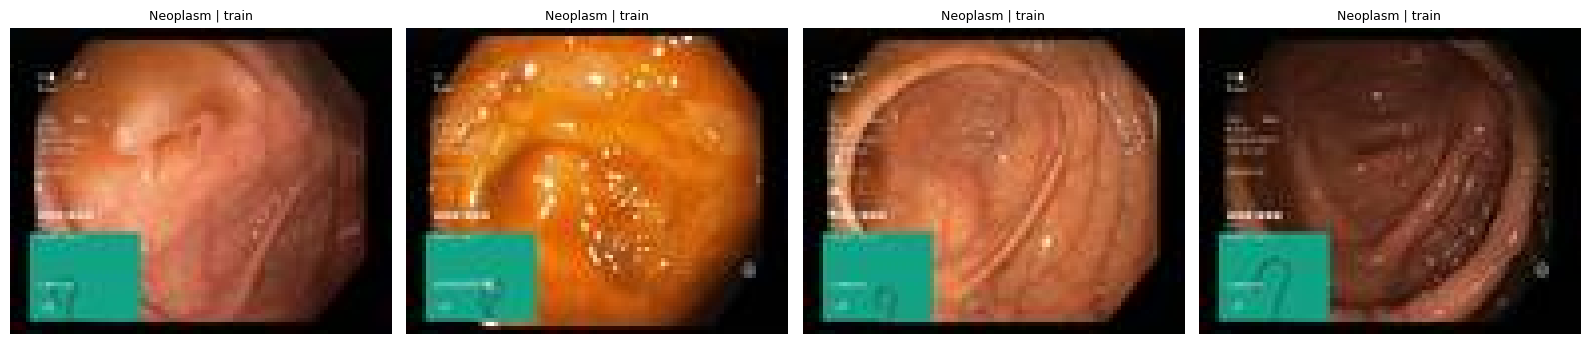

Class: Peritonitis


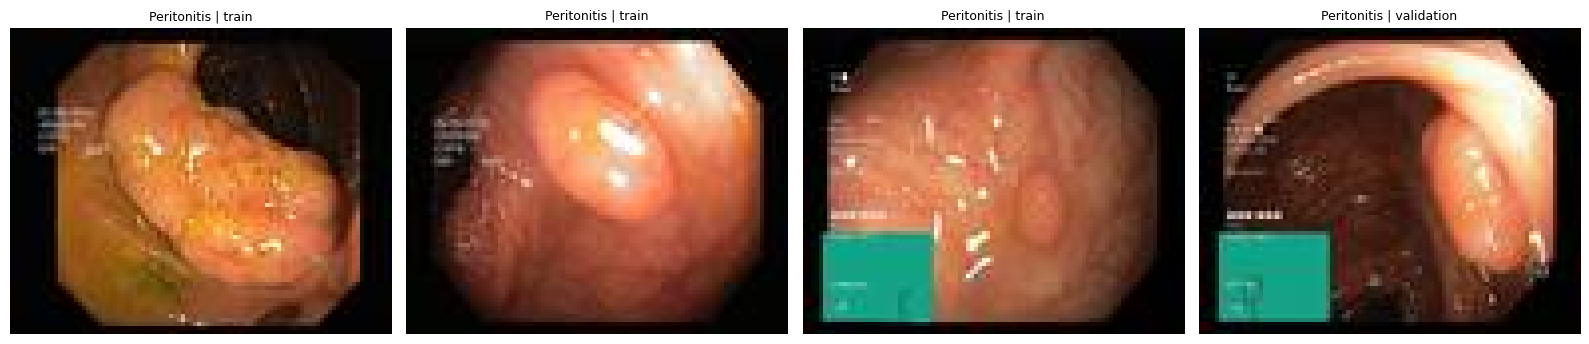

Class: Ureters


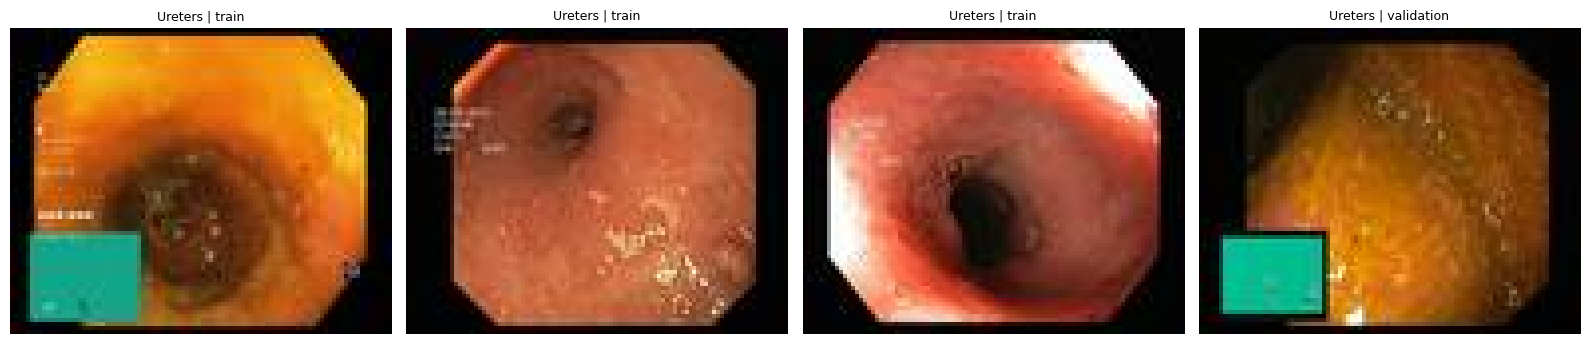

In [23]:

for label in df['label'].unique():
    print("Class:", label)
    show_images(df[df['label'] == label], n=4)


Dataset shape: (4000, 19)
Classes: ['Diverticulosis' 'Neoplasm' 'Peritonitis' 'Ureters']

Thumbnails found: 4000 / 4000
label
Diverticulosis    1000
Neoplasm          1000
Peritonitis       1000
Ureters           1000
Name: exists, dtype: int64


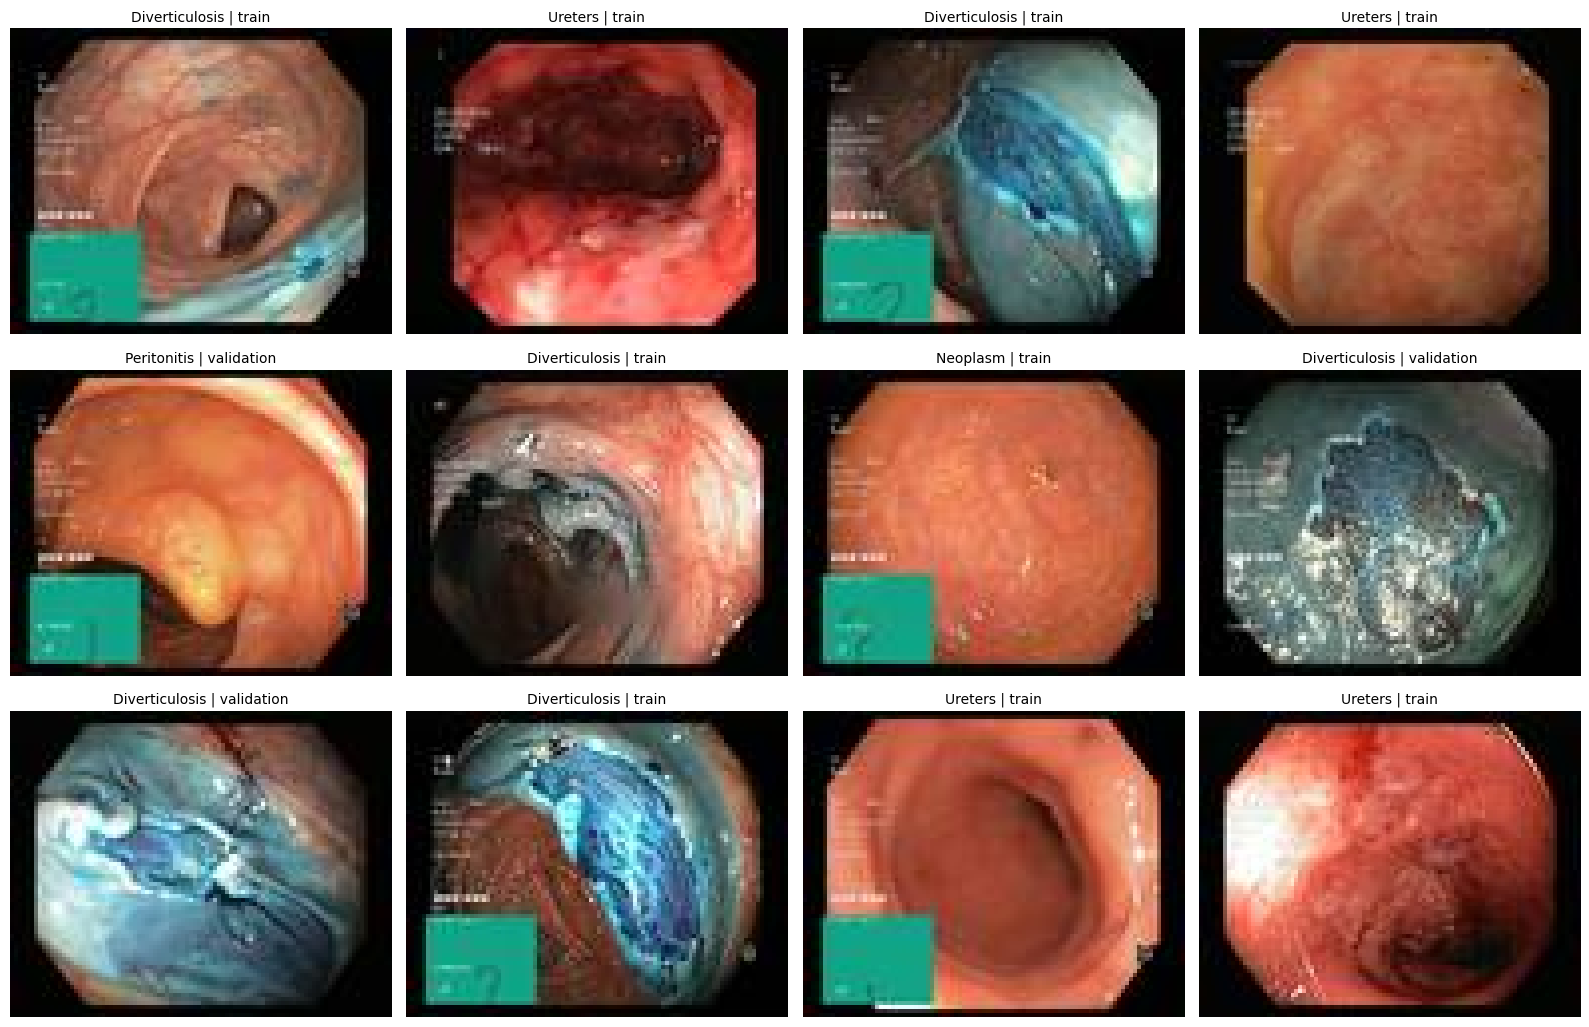

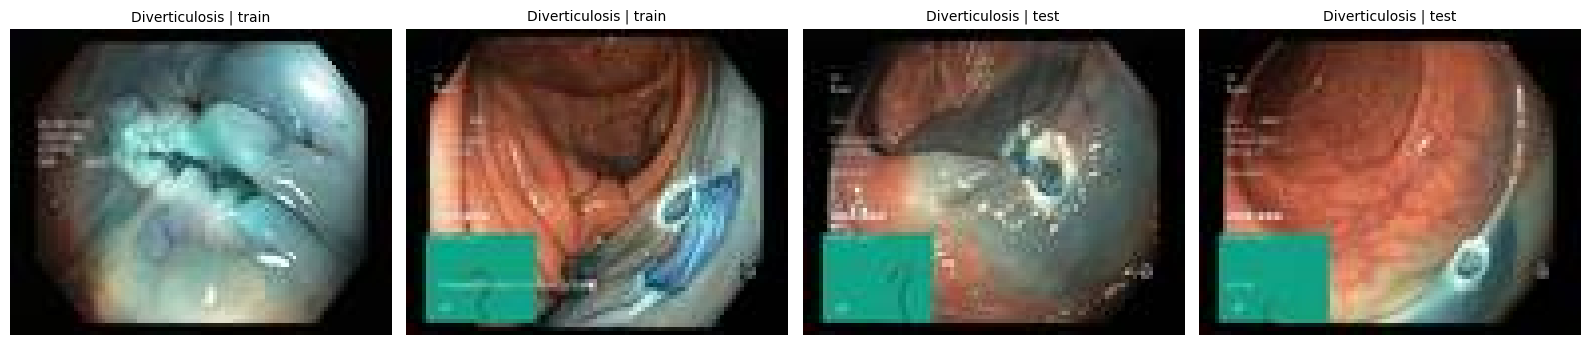

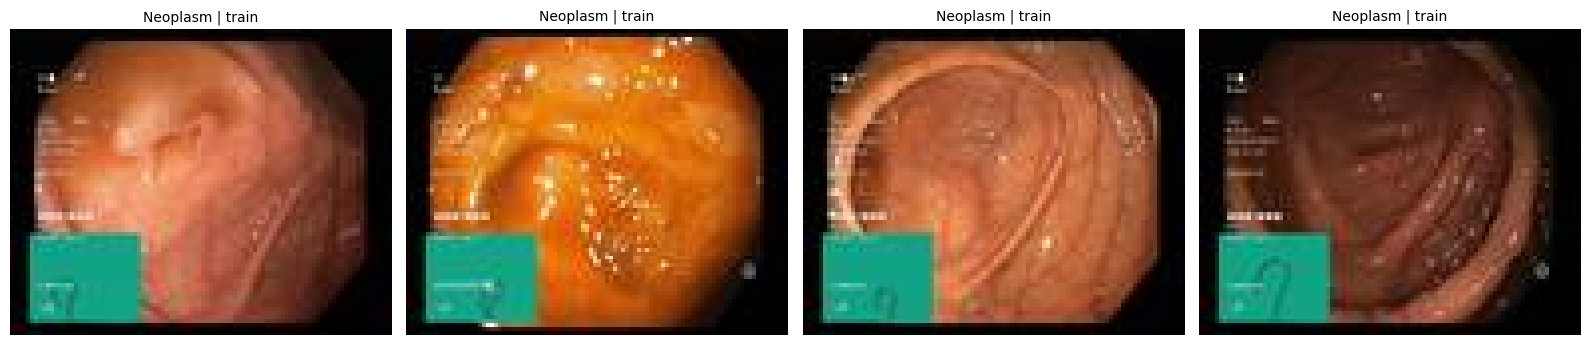

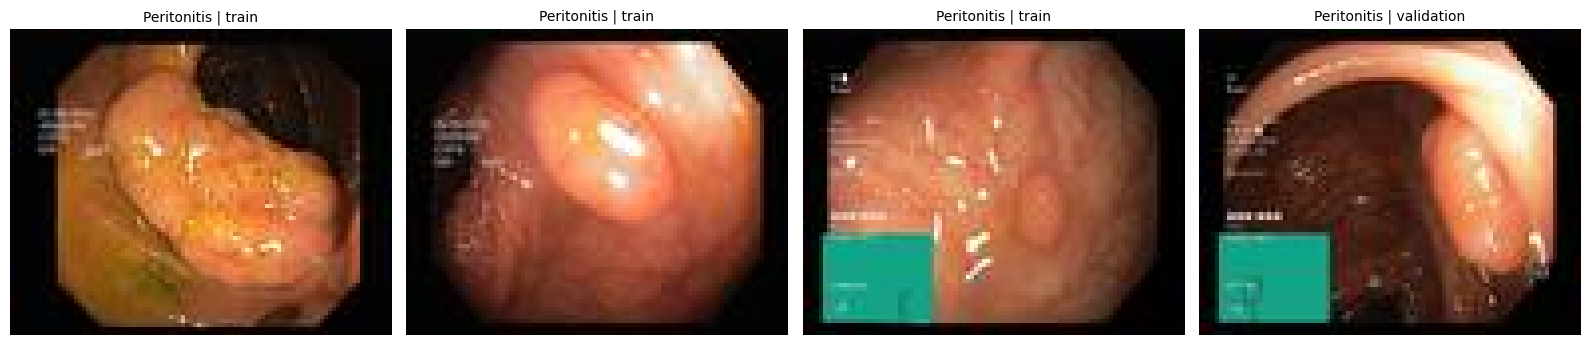

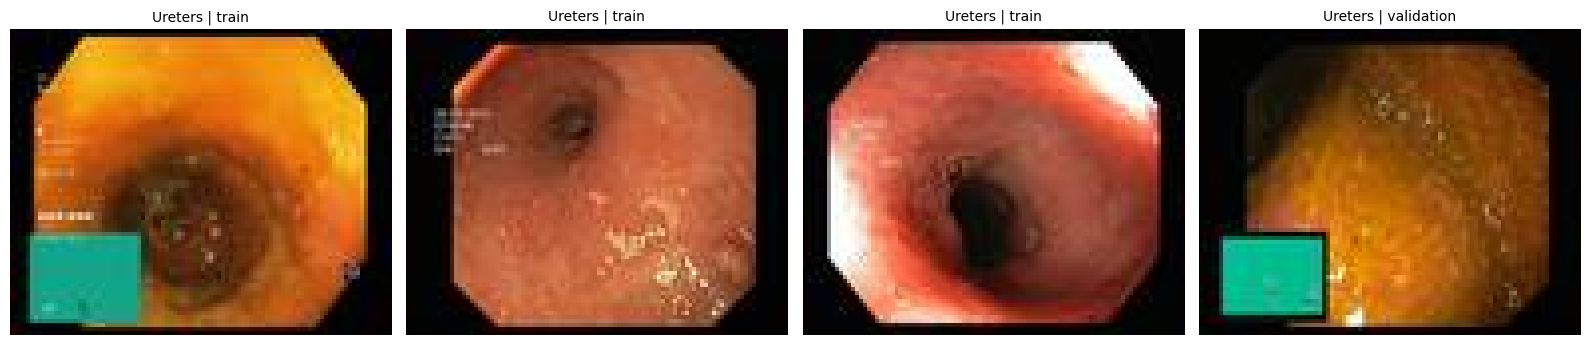

In [25]:

import os
import base64
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

CSV = '/kaggle/input/datasets/sakethbirru/medical-dataset/medical_dataset (1).csv'

# 1) Load CSV
df = pd.read_csv(CSV)

print("Dataset shape:", df.shape)
print("Classes:", df['label'].unique())

# 2) Check thumbnails
df['exists'] = df['thumbnail'].apply(
    lambda x: isinstance(x, str) and x.startswith('data:image/')
)

print(f"\nThumbnails found: {df['exists'].sum()} / {len(df)}")
print(df.groupby('label')['exists'].sum())

# 3) Show images directly from CSV thumbnails
def show_images(data, n=12, cols=4, seed=42):
    data = data[data['exists']]

    if data.empty:
        print("No thumbnails available.")
        return

    sample = data.sample(min(n, len(data)), random_state=seed)
    rows = (len(sample) + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(4 * cols, 3.5 * rows),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis('off')

    for ax, (_, r) in zip(axes.flat, sample.iterrows()):
        try:
            encoded = r['thumbnail'].split(',', 1)[1]
            image_bytes = base64.b64decode(encoded)

            with Image.open(BytesIO(image_bytes)) as img:
                ax.imshow(img.convert('RGB'))

            ax.set_title(f"{r['label']} | {r['split']}", fontsize=10)

        except Exception as e:
            ax.set_title(f"Image error: {e}", fontsize=8)

    plt.tight_layout()
    plt.show()

# 12 random images
show_images(df)

# 4 images from each class
for lab in df['label'].unique():
    show_images(df[df['label'] == lab], n=4)


Images loaded: 4000
Classes: ['Diverticulosis' 'Neoplasm' 'Peritonitis' 'Ureters']
Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 124ms/step - accuracy: 0.4898 - loss: 1.0478 - val_accuracy: 0.6375 - val_loss: 0.8277
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.5906 - loss: 0.8614 - val_accuracy: 0.7063 - val_loss: 0.7631
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.6504 - loss: 0.7911 - val_accuracy: 0.7219 - val_loss: 0.6863
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.6852 - loss: 0.7269 - val_accuracy: 0.7484 - val_loss: 0.5930
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 11s 128ms/step - accuracy: 0.6875 - loss: 0.6849 - val_accuracy: 0.7609 - val_loss: 0.5867
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.7145 - loss: 0.6493 - val_accuracy: 0.7578 - val_loss: 0.5745
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.7230 - loss: 0.6354 - val_accuracy: 0.7594 - val_loss: 0.5537
Epoch 8/10
80/

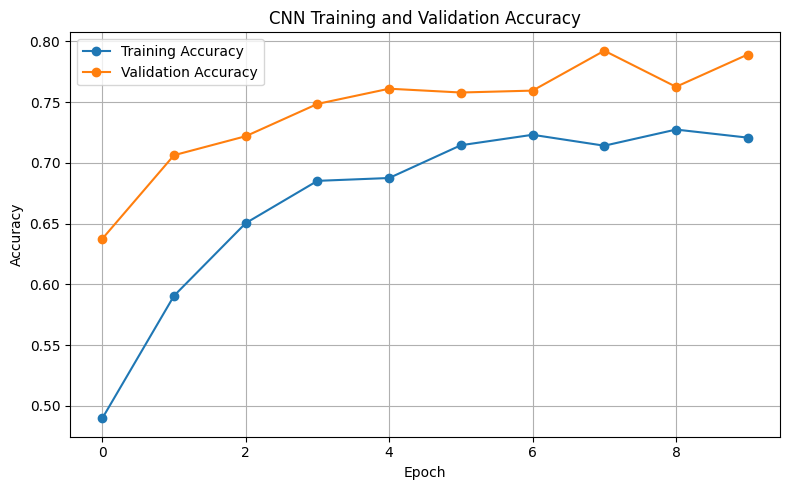

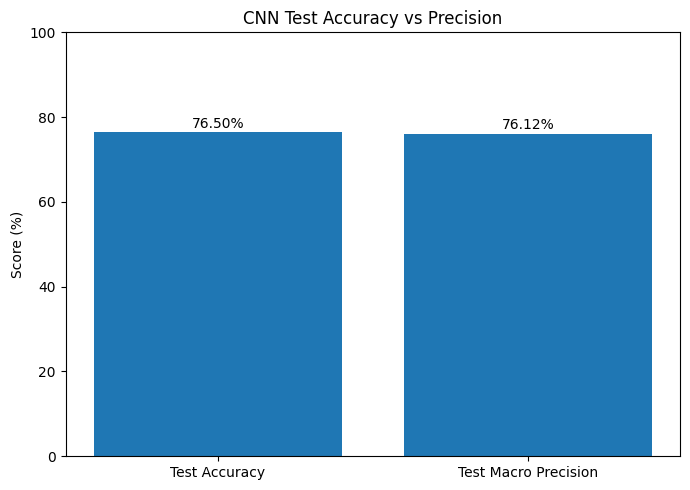

In [43]:
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from io import BytesIO
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, classification_report
)

# 1. Decode thumbnails into small RGB images
IMG_SIZE = 96

images = []
labels = []

for _, row in df.iterrows():
    thumbnail = row.get("thumbnail")

    if not isinstance(thumbnail, str) or not thumbnail.startswith("data:image/"):
        continue

    try:
        encoded = thumbnail.split(",", 1)[1]
        img = Image.open(BytesIO(base64.b64decode(encoded)))
        img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))

        images.append(np.array(img, dtype=np.uint8))
        labels.append(row["label"])
    except Exception:
        continue

X = np.array(images, dtype=np.uint8)
y_text = np.array(labels)

print("Images loaded:", len(X))
print("Classes:", np.unique(y_text))

if len(X) == 0:
    raise ValueError("No usable thumbnails found in the CSV.")

# 2. Encode labels
encoder = LabelEncoder()
y = encoder.fit_transform(y_text)
num_classes = len(encoder.classes_)

# 3. Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Normalize image pixels
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# 4. Build a simple CNN
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. Train the model and save history
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=32,
    verbose=1
)

# 6. Evaluate on the held-out test set
probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print(f"\nTest Accuracy: {accuracy * 100:.2f}%")
print(f"Macro Precision: {precision * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=encoder.classes_,
    zero_division=0
))

# 7. Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. Plot test accuracy and macro precision
plt.figure(figsize=(7, 5))
metric_names = ["Test Accuracy", "Test Macro Precision"]
metric_values = [accuracy * 100, precision * 100]

bars = plt.bar(metric_names, metric_values)
plt.title("CNN Test Accuracy vs Precision")
plt.ylabel("Score (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [46]:

import os
import time
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from io import BytesIO
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)

IMG_SIZE = 96
SEED = 42

# Decode thumbnail images from the CSV
images, labels = [], []

for _, row in df.iterrows():
    thumbnail = row.get("thumbnail")

    if not isinstance(thumbnail, str) or not thumbnail.startswith("data:image/"):
        continue

    try:
        image_bytes = base64.b64decode(thumbnail.split(",", 1)[1])
        img = Image.open(BytesIO(image_bytes)).convert("RGB")
        img = img.resize((IMG_SIZE, IMG_SIZE))

        images.append(np.array(img, dtype=np.uint8))
        labels.append(row["label"])
    except Exception:
        continue

if not images:
    raise ValueError("No valid thumbnails found in the CSV.")

X = np.asarray(images, dtype=np.float32) / 255.0

encoder = LabelEncoder()
y = encoder.fit_transform(labels)
classes = encoder.classes_
NUM_CLASSES = len(classes)

# 80% development data, 20% final test data
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Split development data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.20,
    random_state=SEED,
    stratify=y_dev
)

print("Images loaded:", len(X))
print("Classes:", list(classes))
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


Images loaded: 4000
Classes: [np.str_('Diverticulosis'), np.str_('Neoplasm'), np.str_('Peritonitis'), np.str_('Ureters')]
Training: 2560
Validation: 640
Testing: 800


Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 254ms/step - accuracy: 0.5477 - loss: 0.9863 - val_accuracy: 0.6500 - val_loss: 0.7827
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 249ms/step - accuracy: 0.6504 - loss: 0.7871 - val_accuracy: 0.6516 - val_loss: 0.7552
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 252ms/step - accuracy: 0.6762 - loss: 0.7231 - val_accuracy: 0.6672 - val_loss: 0.7384
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 261ms/step - accuracy: 0.6965 - loss: 0.6848 - val_accuracy: 0.6672 - val_loss: 0.7160
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 249ms/step - accuracy: 0.6926 - loss: 0.6791 - val_accuracy: 0.7047 - val_loss: 0.6303
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 21s 263ms/step - accuracy: 0.7211 - loss: 0.6399 - val_accuracy: 0.7047 - val_loss: 0.6372
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 248ms/step - accuracy: 0.7063 - loss: 0.6330 - val_accuracy: 0.7203 - val_loss: 0.6017
Epoch 8/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 246ms/step - accuracy: 0.7156 - loss: 0.6147 - val_accu

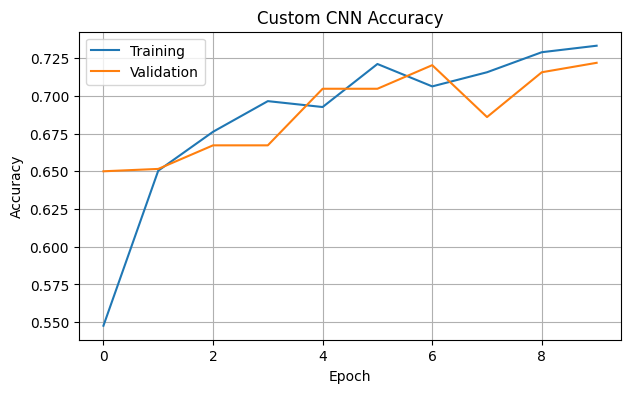

In [47]:
# CNN MODEL
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

model_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

history_cnn = model_cnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)

time_cnn = (time.time() - start) / 60

pred_cnn = np.argmax(model_cnn.predict(X_test, verbose=0), axis=1)

def evaluate_model(name, y_true, y_pred):
    result = {
        "Model": name,
        "Test Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Macro Precision (%)": round(
            precision_score(y_true, y_pred, average="macro",
                            zero_division=0) * 100, 2),
        "Macro Recall (%)": round(
            recall_score(y_true, y_pred, average="macro",
                         zero_division=0) * 100, 2),
        "Macro F1 (%)": round(
            f1_score(y_true, y_pred, average="macro",
                     zero_division=0) * 100, 2)
    }
    print("\n", name)
    print(pd.Series(result).to_string(index=False))
    print("Training time (minutes):", round(time_cnn, 2))
    print(classification_report(
        y_true, y_pred, labels=np.arange(NUM_CLASSES),
        target_names=classes, zero_division=0
    ))
    return result

result_cnn = evaluate_model("Custom CNN", y_test, pred_cnn)

plt.figure(figsize=(7, 4))
plt.plot(history_cnn.history["accuracy"], label="Training")
plt.plot(history_cnn.history["val_accuracy"], label="Validation")
plt.title("Custom CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

model_cnn.save("/kaggle/working/custom_cnn.keras")


Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 76s 594ms/step - accuracy: 0.6098 - loss: 0.9116 - val_accuracy: 0.2500 - val_loss: 1.3867
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 47s 587ms/step - accuracy: 0.7305 - loss: 0.6365 - val_accuracy: 0.2500 - val_loss: 1.3937
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 47s 581ms/step - accuracy: 0.7828 - loss: 0.5224 - val_accuracy: 0.2500 - val_loss: 1.4165
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 46s 576ms/step - accuracy: 0.8164 - loss: 0.4642 - val_accuracy: 0.2500 - val_loss: 1.4936
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 44s 552ms/step - accuracy: 0.8410 - loss: 0.4017 - val_accuracy: 0.2500 - val_loss: 1.5530
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 43s 539ms/step - accuracy: 0.8520 - loss: 0.4042 - val_accuracy: 0.2500 - val_loss: 1.6347
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 44s 545ms/step - accuracy: 0.8836 - loss: 0.3075 - val_accuracy: 0.2500 - val_loss: 1.7269
Epoch 8/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 43s 538ms/step - accuracy: 0.8941 - loss: 0.2750 - val_accu

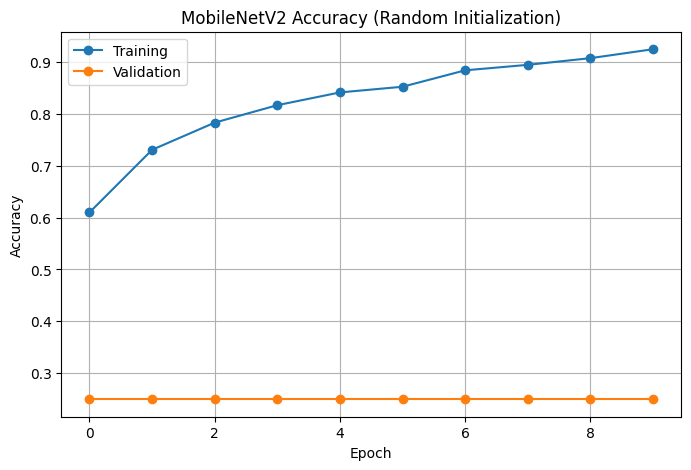

In [50]:

# MODEL 2: MobileNetV2 (without pretrained weights)

import time
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

# No internet download required
base_mobilenet = tf.keras.applications.MobileNetV2(
    weights=None,
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Images are already normalized to [0, 1]
x = base_mobilenet(inputs, training=True)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    NUM_CLASSES, activation="softmax"
)(x)

model_mobilenet = tf.keras.Model(inputs, outputs)

model_mobilenet.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

history_mobilenet = model_mobilenet.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)

time_mobilenet = (time.time() - start) / 60

# Evaluate on test set
pred_mobilenet = np.argmax(
    model_mobilenet.predict(X_test, verbose=0), axis=1
)

print("\nMOBILENETV2 RESULTS")
print(f"Training accuracy: {history_mobilenet.history['accuracy'][-1] * 100:.2f}%")
print(f"Validation accuracy: {history_mobilenet.history['val_accuracy'][-1] * 100:.2f}%")
print(f"Test accuracy: {accuracy_score(y_test, pred_mobilenet) * 100:.2f}%")
print(f"Macro precision: {precision_score(y_test, pred_mobilenet, average='macro', zero_division=0) * 100:.2f}%")
print(f"Macro recall: {recall_score(y_test, pred_mobilenet, average='macro', zero_division=0) * 100:.2f}%")
print(f"Macro F1-score: {f1_score(y_test, pred_mobilenet, average='macro', zero_division=0) * 100:.2f}%")
print(f"Training time: {time_mobilenet:.2f} minutes")

# Accuracy chart
plt.figure(figsize=(8, 5))
plt.plot(history_mobilenet.history["accuracy"], marker="o", label="Training")
plt.plot(history_mobilenet.history["val_accuracy"], marker="o", label="Validation")
plt.title("MobileNetV2 Accuracy (Random Initialization)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

model_mobilenet.save("/kaggle/working/mobilenetv2.keras")


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 3, 3, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 4,012,672 (15.31 MB)

 Non-trainable params: 42,023 (164.16 KB)

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 107s 846ms/step - accuracy: 0.4074 - loss: 1.2639 - val_accuracy: 0.2500 - val_loss: 1.4137
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 63s 789ms/step - accuracy: 0.6125 - loss: 0.9293 - val_accuracy: 0.2500 - val_loss: 1.5311
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 64s 799ms/step - accuracy: 0.6938 - loss: 0.7066 - val_accuracy: 0.2500 - val_loss: 1.5590
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 63s 787ms/step - accuracy: 0.7711 - loss: 0.5498 - val_accuracy: 0.2500 - val_loss: 1.6240
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 65s 807ms/step - accuracy: 0.8320 - loss: 0.4301 - val_accuracy: 0.2500 - val_loss: 1.6747
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 65s 817ms/step - accuracy: 0.8754 - loss: 0.3268 - val_accuracy: 0.2500 - val_loss: 1.6111
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 66s 824ms/step - accuracy: 0.9012 - loss: 0.2667 - val_accuracy: 0.3406 - val_loss: 1.3378
Epoch 8/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 62s 779ms/step - accuracy: 0.9211 - loss: 0.2247 - val_acc

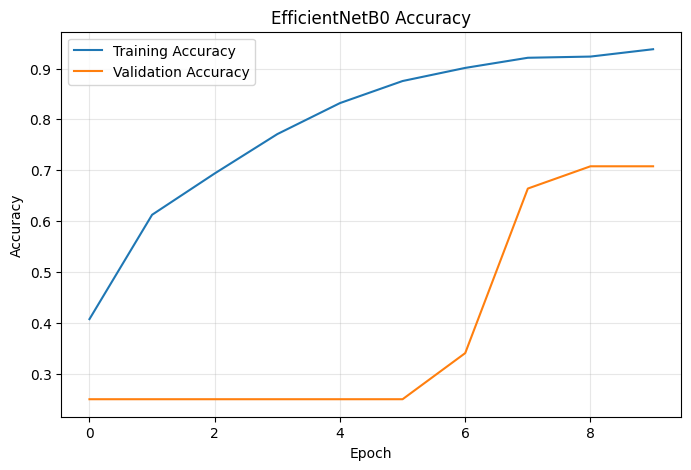

Model saved successfully.


In [52]:

# ============================================================
# MODEL 3: EFFICIENTNETB0
# ============================================================

import time
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Clear previous model session
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

# Create EfficientNetB0 WITHOUT downloading ImageNet weights
base_efficientnet = tf.keras.applications.EfficientNetB0(
    weights=None,                 # IMPORTANT: no download
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Train the backbone because it has randomly initialized weights
base_efficientnet.trainable = True

# Build the classification model
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Your images are already normalized to [0, 1].
# EfficientNetB0 includes its own input rescaling.
x = base_efficientnet(inputs)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model_efficientnet = tf.keras.Model(inputs, outputs)

# Compile model
model_efficientnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_efficientnet.summary()

# Train model
start_time = time.time()

history_efficientnet = model_efficientnet.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)

time_efficientnet = (time.time() - start_time) / 60

# Evaluate on test data
pred_efficientnet = np.argmax(
    model_efficientnet.predict(X_test, verbose=0),
    axis=1
)

print("\n===== EFFICIENTNETB0 RESULTS =====")

print(
    f"Training Accuracy: "
    f"{history_efficientnet.history['accuracy'][-1] * 100:.2f}%"
)

print(
    f"Validation Accuracy: "
    f"{history_efficientnet.history['val_accuracy'][-1] * 100:.2f}%"
)

print(
    f"Test Accuracy: "
    f"{accuracy_score(y_test, pred_efficientnet) * 100:.2f}%"
)

print(
    f"Macro Precision: "
    f"{precision_score(y_test, pred_efficientnet, average='macro', zero_division=0) * 100:.2f}%"
)

print(
    f"Macro Recall: "
    f"{recall_score(y_test, pred_efficientnet, average='macro', zero_division=0) * 100:.2f}%"
)

print(
    f"Macro F1-score: "
    f"{f1_score(y_test, pred_efficientnet, average='macro', zero_division=0) * 100:.2f}%"
)

print(f"Training Time: {time_efficientnet:.2f} minutes")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        pred_efficientnet,
        labels=np.arange(NUM_CLASSES),
        target_names=classes,
        zero_division=0
    )
)

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(
    history_efficientnet.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history_efficientnet.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("EfficientNetB0 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Save the trained model
model_efficientnet.save(
    "/kaggle/working/efficientnetb0.keras"
)

print("Model saved successfully.")


,Model,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-score (%),Training Time (min)
0,Custom CNN,73.32,72.19,73.38,74.26,73.37,72.17,3.39
1,MobileNetV2,92.42,25.00,25.00,6.25,25.00,10.00,7.94
2,EfficientNetB0,93.79,70.78,71.00,71.97,71.00,69.55,11.33


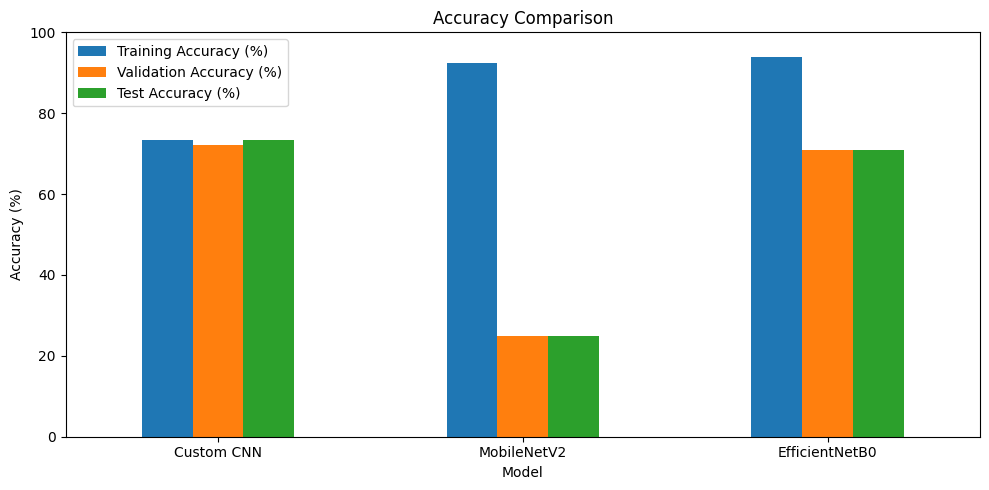

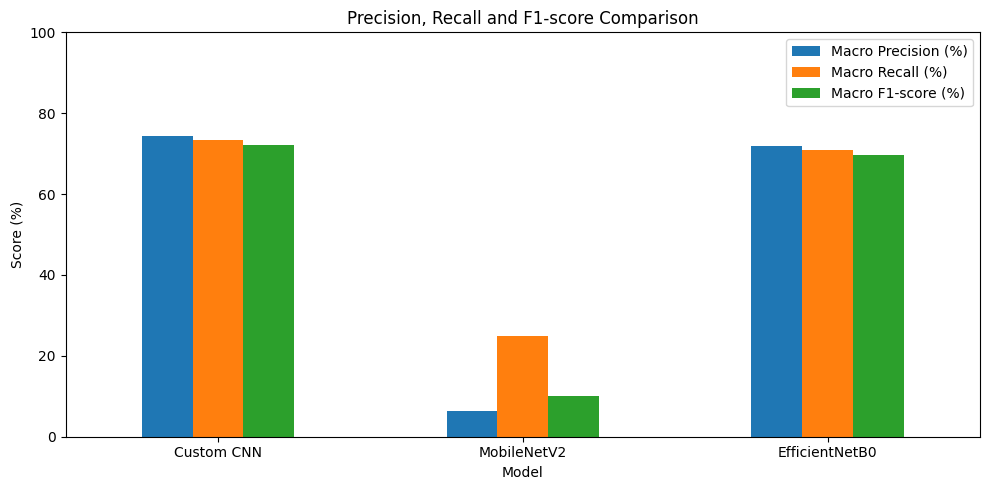

In [53]:
# Final comparision Table Charts

# Collect real metrics from all models
def collect_result(name, history, y_true, y_pred, training_minutes):
    return {
        "Model": name,
        "Training Accuracy (%)": round(
            history.history["accuracy"][-1] * 100, 2
        ),
        "Validation Accuracy (%)": round(
            history.history["val_accuracy"][-1] * 100, 2
        ),
        "Test Accuracy (%)": round(
            accuracy_score(y_true, y_pred) * 100, 2
        ),
        "Macro Precision (%)": round(
            precision_score(y_true, y_pred, average="macro",
                            zero_division=0) * 100, 2
        ),
        "Macro Recall (%)": round(
            recall_score(y_true, y_pred, average="macro",
                         zero_division=0) * 100, 2
        ),
        "Macro F1-score (%)": round(
            f1_score(y_true, y_pred, average="macro",
                     zero_division=0) * 100, 2
        ),
        "Training Time (min)": round(training_minutes, 2)
    }

results_df = pd.DataFrame([
    collect_result("Custom CNN", history_cnn, y_test, pred_cnn, time_cnn),
    collect_result("MobileNetV2", history_mobilenet, y_test,
                   pred_mobilenet, time_mobilenet),
    collect_result("EfficientNetB0", history_efficientnet, y_test,
                   pred_efficientnet, time_efficientnet)
])

display(results_df)
results_df.to_csv(
    "/kaggle/working/three_model_results.csv", index=False
)

# Accuracy comparison
results_df.plot(
    x="Model", y=["Training Accuracy (%)", "Validation Accuracy (%)",
                  "Test Accuracy (%)"],
    kind="bar", figsize=(10, 5), ylim=(0, 100)
)
plt.title("Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Precision, recall and F1 comparison
results_df.plot(
    x="Model",
    y=["Macro Precision (%)", "Macro Recall (%)", "Macro F1-score (%)"],
    kind="bar", figsize=(10, 5), ylim=(0, 100)
)
plt.title("Precision, Recall and F1-score Comparison")
plt.ylabel("Score (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [54]:

def predict_class(image_array, model):
    image_array = np.asarray(image_array, dtype=np.float32)

    if image_array.max() > 1:
        image_array = image_array / 255.0

    image_array = np.expand_dims(image_array, axis=0)
    probabilities = model.predict(image_array, verbose=0)[0]
    index = np.argmax(probabilities)

    return {
        "Predicted class": classes[index],
        "Confidence (%)": round(float(probabilities[index]) * 100, 2)
    }

print("Custom CNN:", predict_class(X_test[0], model_cnn))
print("MobileNetV2:", predict_class(X_test[0], model_mobilenet))
print("EfficientNetB0:", predict_class(X_test[0], model_efficientnet))



Custom CNN: {'Predicted class': np.str_('Diverticulosis'), 'Confidence (%)': 99.45}
MobileNetV2: {'Predicted class': np.str_('Peritonitis'), 'Confidence (%)': 82.15}
EfficientNetB0: {'Predicted class': np.str_('Diverticulosis'), 'Confidence (%)': 50.32}
